device = cuda
ps_train max_n = 324
ps_valid max_n = 324
ps_test max_n = 324
global max_n = 324

Mean absolute errors:
Mean z1     = 0.131204
Mean z2     = 0.057513
Covariance  = 0.076724
PDF saved: test_mean_scatter.pdf


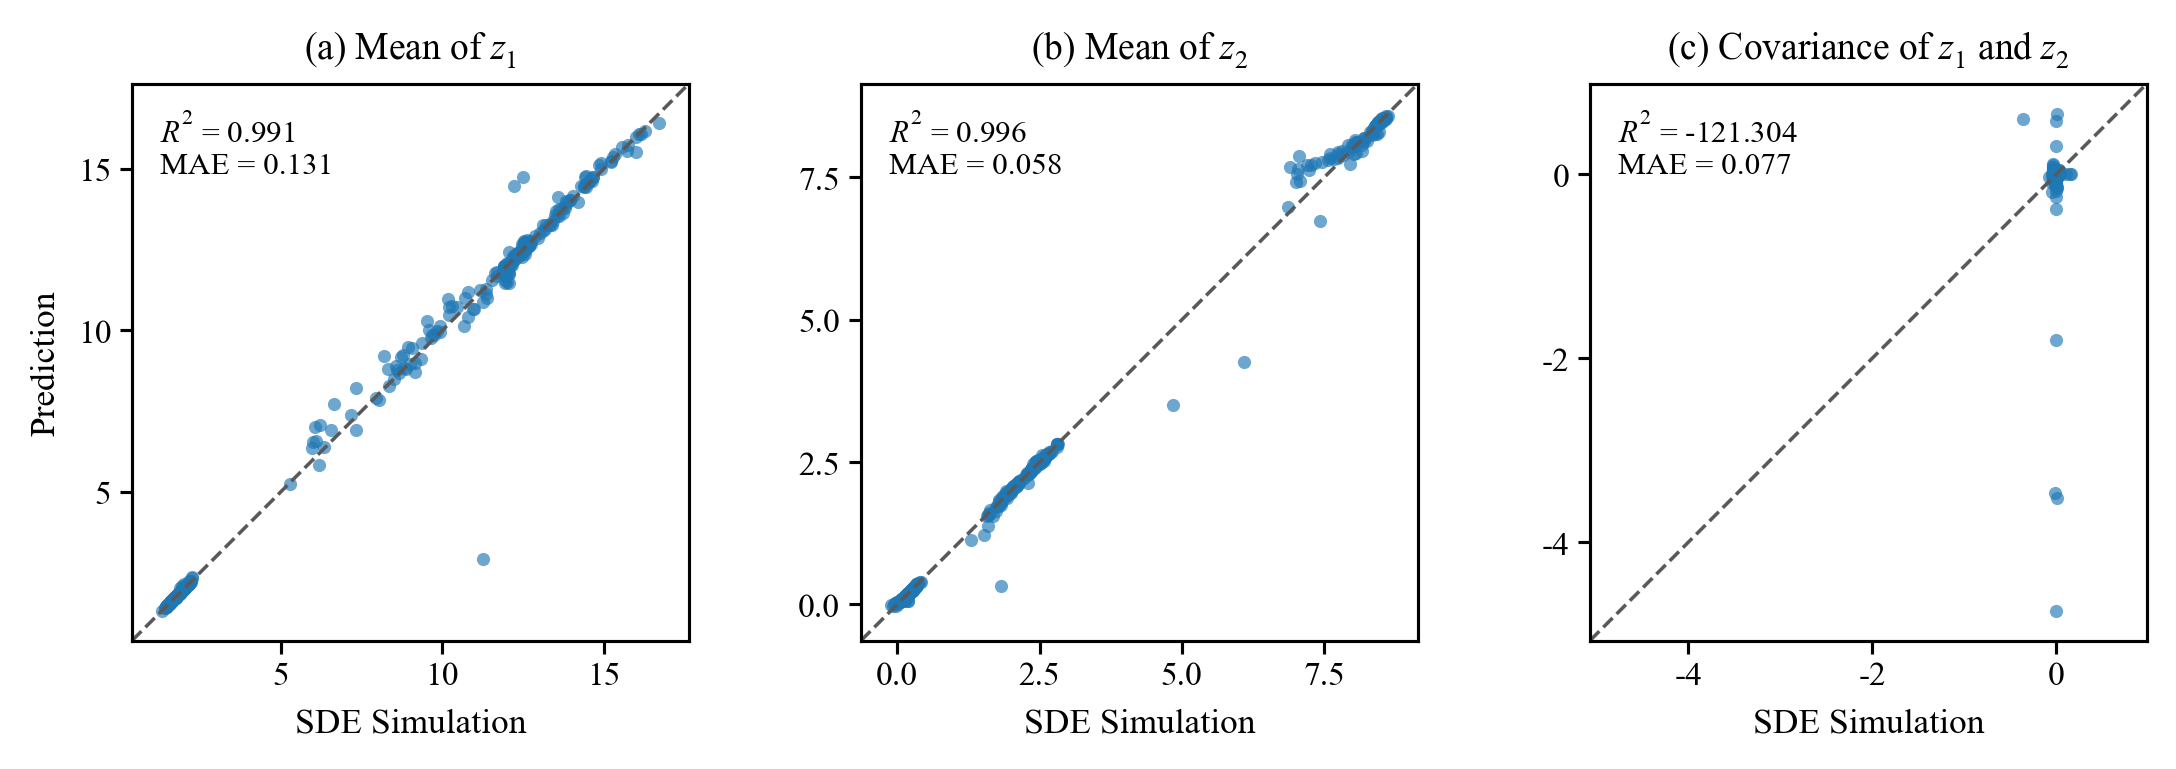

In [2]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator
from scipy.io import loadmat
from torch.utils.data import Dataset, DataLoader


# ======================== 参数设置 ========================
MODEL_PATH = "best_model_in4_K3_512-1024-512_testloss0.097046.pth"
CSV_TEST = "ps_test.csv"

DATA_DIRS = {
    "ps_train": "density_results_ps_train_edges=0.1（未转置）",
    "ps_valid": "density_results_ps_valid_edges=0.1（未转置）",
    "ps_test": "density_results_ps_test_edges=0.1（未转置）",
}

GRID_STEP = 0.1
Z1_MIN = -9.6
Z2_MIN = -9.6
BATCH_SIZE = 8
NUM_WORKERS = 0

SAVE_FIG = True
OUT_PDF = "test_mean_scatter.pdf"


def set_paper_style():
    plt.rcParams.update({
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "font.size": 8.5,
        "axes.labelsize": 8.5,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "axes.linewidth": 0.75,
        "xtick.major.width": 0.75,
        "ytick.major.width": 0.75,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "axes.unicode_minus": False,
        "figure.dpi": 300,
        "savefig.dpi": 600,
    })


class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=4, num_components=3,
                 hidden_dims=(512, 1024, 512)):
        super().__init__()
        dims = [input_dim, *hidden_dims]
        self.num_components = num_components
        self.hidden_layers = nn.ModuleList(
            nn.Linear(dims[i], dims[i + 1])
            for i in range(len(hidden_dims))
        )
        self.output_layer = nn.Linear(hidden_dims[-1], num_components * 6)

    def forward(self, inputs):
        for layer in self.hidden_layers:
            inputs = F.relu(layer(inputs))

        output = self.output_layer(inputs).view(-1, self.num_components, 6)
        weights = F.softmax(output[..., 0], dim=1)
        means = output[..., 1:3]

        s11 = F.softplus(output[..., 3]) + 1e-6
        rho = (2 * torch.sigmoid(output[..., 4]) - 1).clamp(
            -1 + 1e-4, 1 - 1e-4
        )
        s22 = F.softplus(output[..., 5]) + 1e-6
        s12 = rho * torch.sqrt(s11 * s22)

        covariances = torch.stack(
            (
                torch.stack((s11, s12), dim=-1),
                torch.stack((s12, s22), dim=-1),
            ),
            dim=-2,
        )
        return weights, means, covariances


def load_model(path, device):
    model = MixtureOfGaussiansModel().to(device)
    try:
        state_dict = torch.load(path, map_location=device, weights_only=True)
    except TypeError:
        state_dict = torch.load(path, map_location=device)
    model.load_state_dict(state_dict)
    return model.eval()


def mat_filename(prefix, sample_id):
    return f"{prefix}{{{sample_id}}}.mat"


def find_global_max_n(data_dirs):
    max_sizes = {}
    for prefix, folder in data_dirs.items():
        if not os.path.isdir(folder):
            raise FileNotFoundError(f"找不到文件夹：{folder}")

        files = [
            name for name in os.listdir(folder)
            if name.startswith(prefix) and name.endswith(".mat")
        ]
        if not files:
            raise RuntimeError(f"{folder} 中没有找到 {prefix}{{编号}}.mat")

        sizes = []
        for name in files:
            path = os.path.join(folder, name)
            density = loadmat(path).get("density")
            if density is None or density.ndim != 2 or density.shape[0] != density.shape[1]:
                raise ValueError(f"{path} 中的 density 必须是二维方阵")
            sizes.append(density.shape[0])

        max_sizes[prefix] = max(sizes)
        print(f"{prefix} max_n = {max_sizes[prefix]}")

    global_max_n = max(max_sizes.values())
    print(f"global max_n = {global_max_n}")
    return global_max_n


def build_grid(max_n, step, device):
    centers = torch.arange(max_n, device=device, dtype=torch.float32) * step + step / 2
    return torch.meshgrid(centers, centers, indexing="ij")


def pad_density(density, max_n):
    density = np.asarray(density, dtype=np.float32)
    if density.ndim != 2 or density.shape[0] != density.shape[1]:
        raise ValueError(f"density 必须是二维方阵，当前形状为 {density.shape}")

    pad_size = max_n - density.shape[0]
    if pad_size < 0:
        raise ValueError("density 尺寸大于 global max_n")
    return np.pad(density, ((0, pad_size), (0, pad_size))) if pad_size else density


def normalize_density(density, eps=1e-8):
    density = density + eps
    return density / density.sum(dim=(1, 2), keepdim=True)


@torch.no_grad()
def mog_density_on_grid(weights, means, covariances, grid_1, grid_2, eps=1e-8):
    mu1 = means[..., 0, None, None]
    mu2 = means[..., 1, None, None]
    s11 = covariances[..., 0, 0, None, None]
    s12 = covariances[..., 0, 1, None, None]
    s22 = covariances[..., 1, 1, None, None]

    determinant = (s11 * s22 - s12.square()).clamp_min(1e-12)
    d1 = grid_1[None, None] - mu1
    d2 = grid_2[None, None] - mu2

    exponent = -0.5 * (
        s22 / determinant * d1.square()
        - 2 * s12 / determinant * d1 * d2
        + s11 / determinant * d2.square()
    )
    gaussian = torch.exp(exponent) / (2 * torch.pi * torch.sqrt(determinant))
    density = (weights[..., None, None] * gaussian).sum(dim=1)
    return normalize_density(density, eps)


class TestDataset(Dataset):
    def __init__(self, csv_file, mat_dir, max_n):
        self.parameters = pd.read_csv(csv_file).iloc[:, :4].to_numpy(np.float32)
        self.mat_dir = mat_dir
        self.max_n = max_n

        mat_count = sum(
            name.startswith("ps_test") and name.endswith(".mat")
            for name in os.listdir(mat_dir)
        )
        if mat_count != len(self.parameters):
            raise ValueError(
                f"CSV样本数({len(self.parameters)})与MAT文件数({mat_count})不匹配"
            )

    def __len__(self):
        return len(self.parameters)

    def __getitem__(self, index):
        path = os.path.join(self.mat_dir, mat_filename("ps_test", index + 1))
        density = loadmat(path).get("density")
        if density is None:
            raise KeyError(f"{path} 中未找到 'density'")

        return (
            torch.from_numpy(self.parameters[index]),
            torch.from_numpy(pad_density(density, self.max_n)),
        )


def calculate_moments(density, grid_1, grid_2, z1_min, z2_min):
    """
    未转置矩阵约定：
    第1维对应物理 z2，第2维对应物理 z1。
    """
    mean_coord_1 = (density * grid_1).sum(dim=(1, 2))
    mean_coord_2 = (density * grid_2).sum(dim=(1, 2))
    covariance = (
        density
        * (grid_1 - mean_coord_1[:, None, None])
        * (grid_2 - mean_coord_2[:, None, None])
    ).sum(dim=(1, 2))

    mean_z1 = mean_coord_2 + z1_min
    mean_z2 = mean_coord_1 + z2_min
    return mean_z1, mean_z2, covariance


def calc_r2_mae(reference, prediction):
    reference = np.asarray(reference, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    mae = np.mean(np.abs(reference - prediction))
    ss_res = np.sum((reference - prediction) ** 2)
    ss_tot = np.sum((reference - reference.mean()) ** 2)
    r2 = np.nan if ss_tot < 1e-12 else 1 - ss_res / ss_tot
    return r2, mae


def plot_results(reference, prediction, out_pdf, save_figure=True):
    set_paper_style()
    fig, axes = plt.subplots(
        1, 3, figsize=(7.4, 2.45), dpi=300, constrained_layout=True
    )
    titles = [
        r"(a) Mean of $z_1$",
        r"(b) Mean of $z_2$",
        r"(c) Covariance of $z_1$ and $z_2$",
    ]

    for index, (ax, ref, pred, title) in enumerate(
        zip(axes, reference, prediction, titles)
    ):
        ref, pred = np.asarray(ref), np.asarray(pred)
        lower = min(ref.min(), pred.min())
        upper = max(ref.max(), pred.max())
        margin = 0.06 * (upper - lower) if upper > lower else 0.05
        limits = (lower - margin, upper + margin)

        ax.scatter(ref, pred, s=10, alpha=0.65, c="#1f77b4", linewidths=0)
        ax.plot(limits, limits, "--", linewidth=0.85, color="0.35")
        ax.set(xlim=limits, ylim=limits, title=title, xlabel="SDE Simulation")
        ax.set_ylabel("Prediction" if index == 0 else "")
        ax.set_aspect("equal", adjustable="box")
        ax.set_box_aspect(1)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.tick_params(direction="out", length=3, width=0.75, pad=2)

        r2, mae = calc_r2_mae(ref, pred)
        ax.text(
            0.05, 0.95, f"$R^2$ = {r2:.3f}\nMAE = {mae:.3f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=7.5
        )

    if save_figure:
        fig.savefig(out_pdf, format="pdf", bbox_inches="tight")
        print(f"PDF saved: {out_pdf}")
    plt.show()


def main():
    set_paper_style()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"device = {device}")

    max_n = find_global_max_n(DATA_DIRS)
    grid_1, grid_2 = build_grid(max_n, GRID_STEP, device)
    model = load_model(MODEL_PATH, device)

    loader = DataLoader(
        TestDataset(CSV_TEST, DATA_DIRS["ps_test"], max_n),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    reference_chunks = [[], [], []]
    prediction_chunks = [[], [], []]
    non_blocking = torch.cuda.is_available()

    with torch.no_grad():
        for parameters, reference_density in loader:
            parameters = parameters.to(device, non_blocking=non_blocking)
            reference_density = normalize_density(
                reference_density.to(device, non_blocking=non_blocking)
            )

            weights, means, covariances = model(parameters)
            prediction_density = mog_density_on_grid(
                weights, means, covariances, grid_1, grid_2
            )

            reference_moments = calculate_moments(
                reference_density, grid_1, grid_2, Z1_MIN, Z2_MIN
            )
            prediction_moments = calculate_moments(
                prediction_density, grid_1, grid_2, Z1_MIN, Z2_MIN
            )

            for chunks, values in (
                (reference_chunks, reference_moments),
                (prediction_chunks, prediction_moments),
            ):
                for chunk, value in zip(chunks, values):
                    chunk.append(value.cpu().numpy())

    reference = tuple(np.concatenate(chunks) for chunks in reference_chunks)
    prediction = tuple(np.concatenate(chunks) for chunks in prediction_chunks)

    print("\nMean absolute errors:")
    for label, ref, pred in zip(
        ("Mean z1", "Mean z2", "Covariance"), reference, prediction
    ):
        print(f"{label:<11} = {np.mean(np.abs(ref - pred)):.6f}")

    plot_results(reference, prediction, OUT_PDF, SAVE_FIG)


if __name__ == "__main__":
    main()